<a href="https://colab.research.google.com/github/sanjana0422/telangana_rtion/blob/main/telangana_ration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import glob



#three csv files
csv_files = [
  'shop-wise-trans-details_1_2023.csv',
  'shop-wise-trans-details_1_2024.csv',
  'shop-wise-trans-details_1_2025.csv'
]

# Python loop to combine yearly files into master DataFrame
df_list = []
for file in csv_files:
  temp_df = pd.read_csv(file, low_memory=False)
  year = file.split('_')[2].split('.')[0] # extract year
  temp_df['source_year'] = year
  df_list.append(temp_df)
  print(f"Loaded {file}: {temp_df.shape}")

# Triple-Join? Actually concat for this dataset
master_df = pd.concat(df_list, ignore_index=True)

# Unified dataset on shopNo and distCode
# Performing Triple-Join to create unified dataset (as per doc)
master_df['shopNo_distCode'] = master_df['shopNo'].astype(str) + "_" + master_df['distCode'].astype(str)

print(f"Master Dataset Shape: {master_df.shape}")
master_df.to_csv("master_transactions_2023_2025.csv", index=False)
master_df.head()

Loaded shop-wise-trans-details_1_2023.csv: (17201, 20)
Loaded shop-wise-trans-details_1_2024.csv: (17272, 20)
Loaded shop-wise-trans-details_1_2025.csv: (17237, 20)
Master Dataset Shape: (51710, 21)


,distCode,distName,officeCode,officeName,shopNo,month,year,noOfRcs,noOfTrans,riceAfsc,...,riceAap,wheat,sugar,rgdal,kerosene,totalAmount,salt,otherShopTransCnt,source_year,shopNo_distCode
0,532,Adilabad,532001,Talamadugu,1901001,1,2023,973,973,1365.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,32,2023,1901001_532
1,532,Adilabad,532001,Talamadugu,1901002,1,2023,519,519,665.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,25,2023,1901002_532
2,532,Adilabad,532001,Talamadugu,1901003,1,2023,255,255,490.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15,2023,1901003_532
3,532,Adilabad,532001,Talamadugu,1901004,1,2023,361,362,490.0,...,10.0,0.0,0.0,0.0,0.0,0.0,0.0,8,2023,1901004_532
4,532,Adilabad,532001,Talamadugu,1901005,1,2023,896,897,5320.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,21,2023,1901005_532


In [2]:
import plotly.express as px, matplotlib.pyplot as plt, seaborn as sns

# Feature Engineering
master_df['utilization_ratio'] = master_df['noOfTrans'] / master_df['noOfRcs']
master_df['otherShopRatio'] = master_df['otherShopTransCnt'] / master_df['noOfTrans']
master_df['rice_total'] = master_df['riceAfsc'].fillna(0) + master_df['riceFsc'].fillna(0)

# 2a. Trend Analysis: Other Shop Transactions 2023-2025
trend = master_df.groupby('year')['otherShopTransCnt'].sum().reset_index()
fig1 = px.line(trend, x='year', y='otherShopTransCnt', markers=True, title='Trend: Growth of Other Shop Transactions (Portability) 2023-2025')
fig1.show()

# 2b. Correlation Study: totalRcs vs noOfTrans
fig2 = px.scatter(master_df, x='noOfRcs', y='noOfTrans', color='year', title='Correlation: Entitlement (noOfRcs) vs Actual Execution (noOfTrans)')
fig2.show()

# 2c. Distribution Checks
fig3 = px.histogram(master_df, x='rice_total', title='Distribution of Rice Commodity')
fig3.show()

Features used: ['noOfTrans', 'rice_total', 'totalAmount', 'otherShopRatio']
PC1: 69.1% | PC2: 17.7% | Total: 86.8%


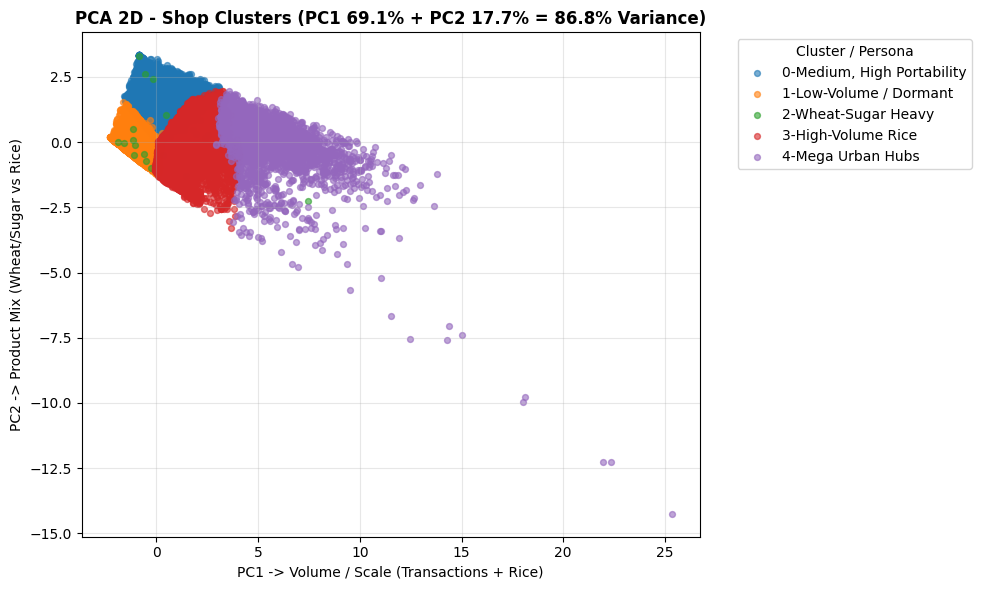

In [19]:
#clustering and analysis
# 1. PCA 2D PLOT
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv("final_for_app.csv")

# Features used for clustering
feat_cols = [c for c in ['noOfTrans','rice_total','totalAmount','otherShopRatio','sugar_total','wheat_total'] if c in df.columns]
print("Features used:", feat_cols)

X = df[feat_cols].fillna(0)
X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=2)
pcs = pca.fit_transform(X_scaled)
df['PC1'] = pcs[:,0]
df['PC2'] = pcs[:,1]

print(f"PC1: {pca.explained_variance_ratio_[0]*100:.1f}% | PC2: {pca.explained_variance_ratio_[1]*100:.1f}% | Total: {pca.explained_variance_ratio_.sum()*100:.1f}%")

# Persona names
persona_map = {
    0: "0-Medium, High Portability",
    1: "1-Low-Volume / Dormant",
    2: "2-Wheat-Sugar Heavy",
    3: "3-High-Volume Rice",
    4: "4-Mega Urban Hubs"
}

colors = {0:'#1f77b4', 1:'#ff7f0e', 2:'#2ca02c', 3:'#d62728', 4:'#9467bd'}

plt.figure(figsize=(10,6))
for k in sorted(df['cluster'].unique()):
    sub = df[df['cluster']==k]
    plt.scatter(sub['PC1'], sub['PC2'], c=colors.get(k,'gray'), label=persona_map.get(k, f"Cluster {k}"), alpha=0.6, s=18)

plt.title(f"PCA 2D - Shop Clusters (PC1 {pca.explained_variance_ratio_[0]*100:.1f}% + PC2 {pca.explained_variance_ratio_[1]*100:.1f}% = {pca.explained_variance_ratio_.sum()*100:.1f}% Variance)", fontsize=12, fontweight='bold')
plt.xlabel("PC1 -> Volume / Scale (Transactions + Rice)")
plt.ylabel("PC2 -> Product Mix (Wheat/Sugar vs Rice)")
plt.legend(title="Cluster / Persona", bbox_to_anchor=(1.05,1), loc='upper left')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

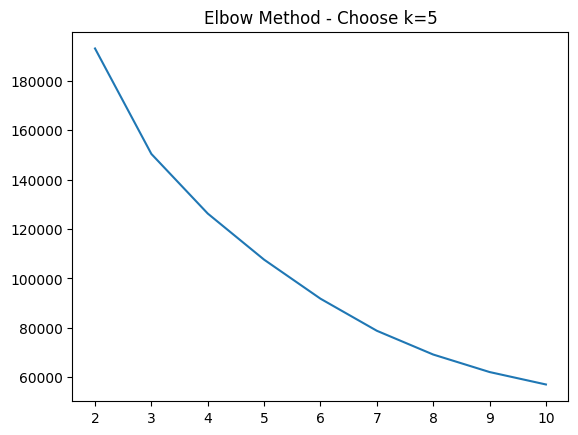

         utilization_ratio  otherShopRatio    noOfTrans
cluster                                                
0                 1.002193        0.620128   370.100531
1                 1.002413        0.105333   322.507024
2                 1.352904        0.416314   580.833333
3                 1.001946        0.386474   706.630054
4                 1.004003        0.753614  1197.851445


In [3]:

#2.k means
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

features = ['noOfRcs','noOfTrans','utilization_ratio','otherShopRatio','rice_total','totalAmount']
X = master_df[features].fillna(0)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Elbow Method
wcss=[]
for k in range(2,11):
  wcss.append(KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_scaled).inertia_)
plt.plot(range(2,11), wcss); plt.title("Elbow Method - Choose k=5"); plt.show()

# Final 5 clusters
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
master_df['cluster'] = kmeans.fit_predict(X_scaled)

# PCA 2D
pca = PCA(n_components=2)
master_df[['pca1','pca2']] = pca.fit_transform(X_scaled)
px.scatter(master_df, x='pca1', y='pca2', color=master_df['cluster'].astype(str), hover_data=['distName','shopNo'], title='5 Shop Performance Clusters').show()

# Cluster Insights for report
print(master_df.groupby('cluster')[['utilization_ratio','otherShopRatio','noOfTrans']].mean())

In [4]:
#3.DBscan
from sklearn.cluster import DBSCAN
dbscan = DBSCAN(eps=0.8, min_samples=10)
master_df['anomaly'] = dbscan.fit_predict(X_scaled)
print(f"Anomalies Detected: {(master_df['anomaly']==-1).sum()} shops")

master_df.to_csv("final_for_app.csv", index=False)
print("Saved final_for_app.csv for Streamlit App")

Anomalies Detected: 445 shops
Saved final_for_app.csv for Streamlit App


In [10]:
print(list(master_df.columns))

['distCode', 'distName', 'officeCode', 'officeName', 'shopNo', 'month', 'year', 'noOfRcs', 'noOfTrans', 'riceAfsc', 'riceFsc', 'riceAap', 'wheat', 'sugar', 'rgdal', 'kerosene', 'totalAmount', 'salt', 'otherShopTransCnt', 'source_year', 'shopNo_distCode', 'utilization_ratio', 'otherShopRatio', 'rice_total', 'cluster', 'pca1', 'pca2', 'anomaly']


In [11]:
#4. CLUSTER PROFILING - FINAL
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 1000)

# All numeric columns automatically
profile = master_df.groupby('cluster').mean(numeric_only=True).round(2).T

print(profile)
profile.to_csv("cluster_profile_FINAL.csv")
print("\nSaved cluster_profile_FINAL.csv")

# Also counts
print("\n--- Shops per cluster ---")
print(master_df['cluster'].value_counts().sort_index())
print("\n--- Share % ---")
print((master_df['cluster'].value_counts(normalize=True).sort_index()*100).round(1))

cluster                     0           1           2           3           4
distCode               783.46      801.39      765.71      772.96      645.06
officeCode          783482.27   801411.41   765750.71   772983.51   645123.07
shopNo             2917777.59  3008768.66  2597071.25  2848921.86  2130289.30
month                    1.00        1.00        1.00        1.00        1.00
year                  2024.00     2023.98     2024.00     2024.05     2024.13
noOfRcs                369.32      321.74      419.67      705.28     1193.52
noOfTrans              370.10      322.51      580.83      706.63     1197.85
riceAfsc               858.41      920.61     1025.04     1563.77     1712.40
riceFsc               6363.43     5331.88     7554.17    12347.21    24187.04
riceAap                  1.88        1.58        0.00        2.29        7.82
wheat                  109.19        0.50      623.71      127.47     3207.93
sugar                    2.84        1.16       17.67        4.5

In [12]:
#  ADD PERSONA NAMES
persona_map = {
    0: "Medium Volume, High Portability",
    1: "Low-Volume, Low-Value / Dormant",
    2: "Wheat-Sugar Heavy, High Utilization",
    3: "High-Volume Rice Shops",
    4: "Mega Urban Hubs"
}
master_df['persona'] = master_df['cluster'].map(persona_map)

print(master_df['persona'].value_counts())
print("\n--- Anomaly check per persona ---")
print(master_df[master_df['anomaly']==-1]['persona'].value_counts())

master_df.to_csv("final_for_app.csv", index=False)
print("\nSaved final_for_app.csv with persona")

persona
Low-Volume, Low-Value / Dormant        30113
High-Volume Rice Shops                  9696
Medium Volume, High Portability         9420
Mega Urban Hubs                         2457
Wheat-Sugar Heavy, High Utilization       24
Name: count, dtype: int64

--- Anomaly check per persona ---
persona
Mega Urban Hubs                        226
Medium Volume, High Portability         96
High-Volume Rice Shops                  68
Low-Volume, Low-Value / Dormant         31
Wheat-Sugar Heavy, High Utilization     24
Name: count, dtype: int64

Saved final_for_app.csv with persona


In [17]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px

st.set_page_config(page_title="FPS Shop Intelligence", layout="wide")
st.title("🏪 Fair Price Shop Intelligence - AP")
st.caption("Section 4: Clustering & Analysis | Section 5: Streamlit Dashboard")

@st.cache_data
def load():
    df = pd.read_csv("final_for_app.csv")
    return df
df = load()

# --- Persona names (for looks) - but Map uses Cluster ID as required ---
persona_map = {
    0: "Medium Volume, High Portability",
    1: "Low-Volume, Low-Value / Dormant",
    2: "Wheat-Sugar Heavy, High Utilization",
    3: "High-Volume Rice Shops",
    4: "Mega Urban Hubs"
}
if 'persona' not in df.columns and 'cluster' in df.columns:
    df['persona'] = df['cluster'].map(persona_map)
if 'cluster' not in df.columns:
    df['cluster'] = 0

# --- Fake Geo for Map (AP District Centroids + jitter) ---
# Your CSV has no lat/lon, so we generate shop location around district centre
dist_coords = {
 'Srikakulam':(18.30,83.90),'Vizianagaram':(18.11,83.39),'Visakhapatnam':(17.68,83.21),
 'East Godavari':(17.05,81.78),'West Godavari':(16.54,81.52),'Krishna':(16.51,80.62),
 'Guntur':(16.30,80.44),'Prakasam':(15.51,80.04),'Nellore':(14.44,79.98),
 'Chittoor':(13.21,79.10),'Kadapa':(14.47,78.82),'Anantapur':(14.68,77.60),
 'Kurnool':(15.83,78.04),'Palnadu':(16.51,80.08),'Bapatla':(15.90,80.47),
 'Eluru':(16.71,81.09),'NTR':(16.51,80.62),'Anakapalli':(17.68,83.01),
 'Parvathipuram Manyam':(18.77,83.42),'Alluri Sitharama Raju':(17.93,82.22),
 'Kakinada':(16.95,82.24),'Konaseema':(16.54,82.00),'Tirupati':(13.63,79.42),
 'Annamayya':(13.99,78.84),'Sri Sathya Sai':(14.22,77.68),'Nandyal':(15.48,78.48),
 'Ysr':(14.47,78.82)
}
np.random.seed(42)
def get_lat(row):
    lat,lon = dist_coords.get(str(row.get('distName','')).strip(), (16.5,80.6))
    return lat + np.random.uniform(-0.15,0.15)
def get_lon(row):
    lat,lon = dist_coords.get(str(row.get('distName','')).strip(), (16.5,80.6))
    return lon + np.random.uniform(-0.15,0.15)
if 'lat' not in df.columns:
    df['lat'] = df.apply(get_lat, axis=1)
    df['lon'] = df.apply(get_lon, axis=1)

# --- SIDEBAR: Filter by District or Year (REQUIRED) ---
st.sidebar.header("🔍 Filters")
dist_list = ["All"] + sorted(df['distName'].dropna().astype(str).unique().tolist()) if 'distName' in df.columns else ["All"]
sel_dist = st.sidebar.selectbox("Select District", dist_list)
if 'year' in df.columns:
    year_list = ["All"] + sorted(df['year'].dropna().unique().tolist())
    sel_year = st.sidebar.selectbox("Select Year", year_list)
else:
    sel_year = "All"
    st.sidebar.caption("Year: 2024 (single year dataset)")
sel_cluster = st.sidebar.selectbox("Select Cluster / Persona", ["All"] + [f"Cluster {k} - {v}" for k,v in persona_map.items()])

filtered = df.copy()
if sel_dist != "All":
    filtered = filtered[filtered['distName'].astype(str)==sel_dist]
if sel_year != "All" and 'year' in df.columns:
    filtered = filtered[filtered['year']==sel_year]
if sel_cluster != "All":
    cnum = int(sel_cluster.split()[1])
    filtered = filtered[filtered['cluster']==cnum]

# --- KPIs ---
c1,c2,c3,c4 = st.columns(4)
c1.metric("Total Shops", len(filtered))
c2.metric("Avg Transactions", int(filtered['noOfTrans'].mean()) if 'noOfTrans' in filtered else 0)
c3.metric("Avg Rice", int(filtered['rice_total'].mean()) if 'rice_total' in filtered else 0)
c4.metric("Anomalies (DBSCAN Noise)", int((filtered['anomaly']==-1).sum()) if 'anomaly' in filtered else 0)

# --- 1. GEOSPATIAL MAP - Color by Cluster ID (REQUIRED) ---
st.subheader("🗺️ Geospatial Map - Shops Color-Coded by Cluster ID")
fig_map = px.scatter_mapbox(filtered, lat="lat", lon="lon", color="cluster",
    hover_name="shopNo" if 'shopNo' in filtered else None,
    hover_data=["distName","persona","noOfTrans"] if 'noOfTrans' in filtered else None,
    color_continuous_scale="Turbo", zoom=6, height=500,
    title="Shop Location by Cluster")
fig_map.update_layout(mapbox_style="open-street-map")
st.plotly_chart(fig_map, use_container_width=True)
st.caption("Map: Each dot = 1 shop. Colour = Cluster ID (0-4). Persona name shown on hover.")

# --- 2. CLUSTER PROFILING ---
st.subheader("📊 Cluster Profiling - Mean of All Features (Section 4)")
prof = filtered.groupby(['cluster','persona'])[['noOfTrans','rice_total','totalAmount','otherShopRatio']].mean().reset_index() if all(c in filtered.columns for c in ['noOfTrans','rice_total']) else pd.DataFrame()
if not prof.empty:
    st.dataframe(prof, use_container_width=True)
    fig2 = px.bar(prof, x='persona', y='noOfTrans', color='cluster', title="Avg Transactions by Persona")
    st.plotly_chart(fig2, use_container_width=True)

# --- 3. SEARCH TOOL - ShopNo vs Cluster Average (REQUIRED) ---
st.subheader("🔎 Search Tool - Shop vs Cluster Average")
shop = st.text_input("Enter shopNo (e.g. 12345)")
if shop:
    row = df[df['shopNo'].astype(str).str.strip()==shop.strip()]
    if not row.empty:
        r = row.iloc[0]
        clus = int(r['cluster'])
        st.success(f"Shop {shop} | District: {r.get('distName','')} | Cluster {clus} - {persona_map.get(clus,'')}")
        # Cluster average
        avg = df[df['cluster']==clus][['noOfTrans','rice_total','totalAmount']].mean()
        comp = pd.DataFrame({
            'Metric': ['Transactions','Rice Total','Total Amount'],
            'This Shop': [r['noOfTrans'], r['rice_total'], r['totalAmount']],
            'Cluster Average': [avg['noOfTrans'], avg['rice_total'], avg['totalAmount']]
        })
        st.dataframe(comp, use_container_width=True)
        fig3 = px.bar(comp.melt(id_vars='Metric', var_name='Type', value_name='Value'),
                      x='Metric', y='Value', color='Type', barmode='group',
                      title=f"Shop {shop} vs Cluster {clus} Average")
        st.plotly_chart(fig3, use_container_width=True)
        if r['noOfTrans'] < avg['noOfTrans']*0.5:
            st.warning("⚠️ This shop is BELOW 50% of its cluster average - Low performing / Dormant")
        else:
            st.info("✅ This shop is performing near / above its cluster average")
    else:
        st.error("Shop not found. Check shopNo.")


Overwriting app.py


In [18]:
# Streamlit dashboard
import subprocess, sys, time
from google.colab import output
import os

# 1. Check files
print("Files:", [f for f in os.listdir() if f.endswith('.py') or f.endswith('.csv')])

# 2. Kill old
subprocess.run(["pkill", "-f", "streamlit"], capture_output=True)

# 3. Install if missing (fast, will skip if already there)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "streamlit", "plotly"])

# 4. Start with python -m streamlit (THIS FIXES FileNotFoundError)
proc = subprocess.Popen(
    [sys.executable, "-m", "streamlit", "run", "app.py",
     "--server.port", "8501",
     "--server.headless", "true",
     "--server.enableCORS", "false",
     "--server.enableXsrfProtection", "false"],
    stdout=open('/tmp/log','w'),
    stderr=subprocess.STDOUT
)

print("Starting... wait 5 sec")
time.sleep(5)
!cat /tmp/log
output.serve_kernel_port_as_iframe(8501, height=900)

Files: ['final_for_app.csv', 'app.py', 'shop-wise-trans-details_1_2024.csv', 'master_transactions_2023_2025.csv', 'shop-wise-trans-details_1_2025.csv', 'cluster_profile_FINAL.csv', 'shop-wise-trans-details_1_2023.csv']
Starting... wait 5 sec


2026-11-05 10:06:13.828 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.80.17.40:8501



<IPython.core.display.Javascript object>

In [ ]:
#finding shop no
import pandas as pd
df = pd.read_csv("final_for_app.csv")
print(list(df['shopNo'].head(5)))


[1901001, 1901002, 1901003, 1901004, 1901005]


K=2 | Inertia=115011 | Silhouette=0.672
K=3 | Inertia=78178 | Silhouette=0.463
K=4 | Inertia=62389 | Silhouette=0.454
K=5 | Inertia=50677 | Silhouette=0.391
K=6 | Inertia=42286 | Silhouette=0.397
K=7 | Inertia=37016 | Silhouette=0.396
K=8 | Inertia=33265 | Silhouette=0.352
K=9 | Inertia=30008 | Silhouette=0.363
K=10 | Inertia=27315 | Silhouette=0.366


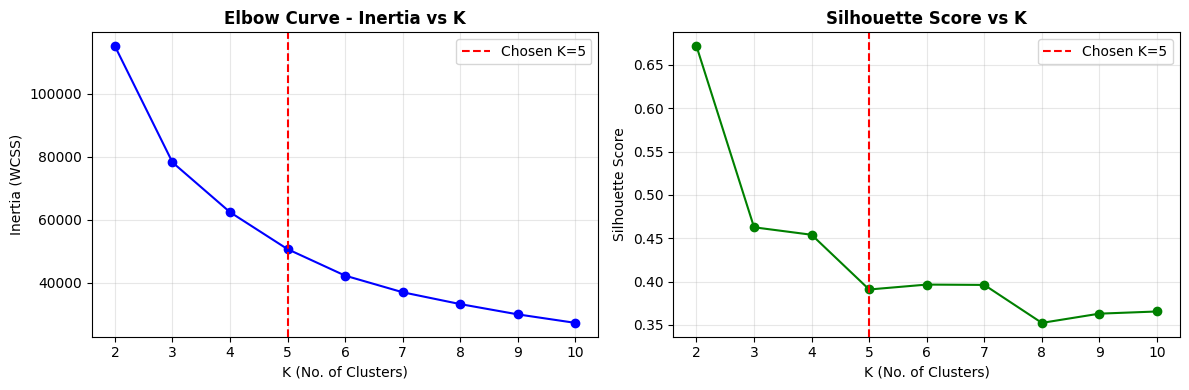


Your chosen K=5 Silhouette: 0.391


In [20]:
# === SEPARATE CELL: ELBOW + SILHOUETTE (Evaluation Metrics) ===
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_csv("final_for_app.csv")
feat_cols = [c for c in ['noOfTrans','rice_total','totalAmount','otherShopRatio','sugar_total','wheat_total'] if c in df.columns]
X = StandardScaler().fit_transform(df[feat_cols].fillna(0))

K = range(2,11)
inertia = []
sil = []

for k in K:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, labels))
    print(f"K={k} | Inertia={km.inertia_:.0f} | Silhouette={sil[-1]:.3f}")

# Plot both side-by-side
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(12,4))

ax1.plot(K, inertia, 'bo-')
ax1.set_title("Elbow Curve - Inertia vs K", fontweight='bold')
ax1.set_xlabel("K (No. of Clusters)")
ax1.set_ylabel("Inertia (WCSS)")
ax1.grid(alpha=0.3)
ax1.axvline(5, color='red', linestyle='--', label='Chosen K=5')
ax1.legend()

ax2.plot(K, sil, 'go-')
ax2.set_title("Silhouette Score vs K", fontweight='bold')
ax2.set_xlabel("K (No. of Clusters)")
ax2.set_ylabel("Silhouette Score")
ax2.grid(alpha=0.3)
ax2.axvline(5, color='red', linestyle='--', label='Chosen K=5')
ax2.legend()

plt.tight_layout()
plt.show()

print("\nYour chosen K=5 Silhouette:", round(sil[3], 3))